# 06: LGD Model Training

This notebook trains six regression models for Loss Given Default (LGD) estimation. Each model is tuned via RandomizedSearchCV on a random sample of 100,000 observations (from the defaulted loans of the development sample, matured loans only) and evaluated on a held-out test set. The model with the best **cross-validated** RMSE is selected for portfolio inference; the test metrics are reported but play no role in the choice.

**Input:** `data/processed/checkpoint_df_LGD_training.pkl`, `data/processed/features_LGD_num_for_training.pkl`, `data/processed/features_LGD_cat_for_training.pkl`, `data/processed/checkpoint_df_master_with_PD.pkl`  
**Output:** `models/<best_model>_LGD.pkl`, `models/LGD_model_comparison.csv`, `models/pipeline_LGD.pkl`, `data/processed/checkpoint_df_master_with_PD_LGD.pkl`

## Libraries

In [1]:
# Run from the repository root so that data/, models/ and src/ resolve the same way
# whether the notebook is opened from the root or from production_notebooks/.
import os
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "production_notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pickle
import shap
import os

from sklearn.model_selection import train_test_split

from train_models_LGD import train_all_models_LGD
from pipeline_LGD     import FeaturePipeline_LGD
from readme_figures   import plot_lgd_model_comparison
from explain          import shap_values_for
from lgd_analysis     import lgd_components, variance_explained, lgd_by_months_paid
from lightgbm         import LGBMRegressor
from sklearn.metrics  import r2_score

## 1. Load Checkpoint

In [3]:
with open("data/processed/checkpoint_df_LGD_training.pkl", "rb") as f:
    data = pickle.load(f)
df_LGD_clean = data["df_LGD_clean"]        # defaulted, matured loans (EDA view of the treatment)

with open("data/processed/features_LGD_num_for_training.pkl", "rb") as f:
    num_features_LGD = pickle.load(f)

with open("data/processed/features_LGD_cat_for_training.pkl", "rb") as f:
    cat_features_LGD = pickle.load(f)

features_LGD = num_features_LGD + cat_features_LGD

# Raw features for every loan (with PD already computed): the LGD pipeline is
# fitted on the raw training rows and applied unchanged to test and portfolio.
with open("data/processed/checkpoint_df_master_with_PD.pkl", "rb") as f:
    df_master_features = pickle.load(f)["df_master_features"]

print(f"LGD development sample: {len(df_LGD_clean):,} defaulted, matured loans")
print(f"Features: {features_LGD}")

LGD development sample: 100,589 defaulted, matured loans
Features: ['interest_rate', 'num_open_credit_lines', 'total_credit_revolving_bal', 'num_inq_in_12mths', 'tot_num_credit_lines', 'used_credit_share', 'annual_income', 'emp_length', 'earliest_cr_line_year', 'mths_since_last_delinq_LGD', 'monthly_payment', 'mths_since_recent_revol_delinq_LGD', 'dept_paym_income_ratio', 'loan_term_months', 'loan_purpose', 'addr_state']


## 2. Train / Test Split

Random split of the defaulted development sample (no stratification, the regression target is continuous).

In [4]:
idx_train, idx_test = train_test_split(df_LGD_clean.index, test_size=0.2, random_state=42)

y_train_LGD = df_LGD_clean.loc[idx_train, "Target_Variable_Loss"]
y_test_LGD  = df_LGD_clean.loc[idx_test, "Target_Variable_Loss"]

print(f"Train: {len(idx_train):,} | Test: {len(idx_test):,}")
print(f"Mean LGD train: {y_train_LGD.mean():.4f} | test: {y_test_LGD.mean():.4f}")

Train: 80,471 | Test: 20,118
Mean LGD train: 52.2540 | test: 52.1842


## 3. Preprocessing

`FeaturePipeline_LGD` is fitted on the raw features of the training split only: outlier and missing-value treatment from `LGD_TREATMENTS`, one-hot encoding of the categorical features and a RobustScaler on the numeric ones. The same fitted object transforms the test split here and the whole portfolio in section 6, so training and scoring cannot drift apart.

In [5]:
pipeline_LGD = FeaturePipeline_LGD().fit(df_master_features.loc[idx_train, features_LGD])

X_train_LGD = pipeline_LGD.transform(df_master_features.loc[idx_train, features_LGD])
X_test_LGD  = pipeline_LGD.transform(df_master_features.loc[idx_test, features_LGD])

print(f"X_train_LGD shape: {X_train_LGD.shape} | X_test_LGD shape: {X_test_LGD.shape}")

annual_income: skew after capping 1.7332 -> log1p not applied
Numeric features without a treatment step: ['interest_rate', 'emp_length', 'mths_since_last_delinq_LGD', 'monthly_payment', 'mths_since_recent_revol_delinq_LGD', 'loan_term_months']


X_train_LGD shape: (80471, 76) | X_test_LGD shape: (20118, 76)


## 4. Model Training

Six regression models are trained:
- Ridge Regression (interpretable baseline with L2 regularization)
- Decision Tree
- Random Forest
- XGBoost
- LightGBM
- CatBoost

All models tuned via RandomizedSearchCV (100k sample, 5-fold CV, optimizing RMSE). Results saved to `models/`.

In [6]:
results_LGD = train_all_models_LGD(
    X_train_LGD, y_train_LGD,
    X_test_LGD,  y_test_LGD,
    sample_size=100_000
)


────────────────────────────────────────────────────────────
  Training: ridge_LGD
────────────────────────────────────────────────────────────
  Sampling 80,471 rows for hyperparameter search...
  Running RandomizedSearchCV (50 iterations, 5-fold CV)...


  Best params  : {'alpha': np.float64(97.38555188414593), 'fit_intercept': True}
  Best CV RMSE : 22.7536
  Refitting on full training set (80,471 rows)...
  Test RMSE: 22.7043 | MAE: 18.9493 | R²: 0.059
  Saved: models\ridge_LGD.pkl | models\ridge_LGD_metrics.json

────────────────────────────────────────────────────────────
  Training: decision_tree_LGD
────────────────────────────────────────────────────────────
  Sampling 80,471 rows for hyperparameter search...
  Running RandomizedSearchCV (50 iterations, 5-fold CV)...


  Best params  : {'max_depth': 5, 'min_samples_leaf': 100, 'min_samples_split': 469}
  Best CV RMSE : 22.8716
  Refitting on full training set (80,471 rows)...


  Test RMSE: 22.8293 | MAE: 19.0352 | R²: 0.0487
  Saved: models\decision_tree_LGD.pkl | models\decision_tree_LGD_metrics.json

────────────────────────────────────────────────────────────
  Training: random_forest_LGD
────────────────────────────────────────────────────────────
  Sampling 80,471 rows for hyperparameter search...
  Running RandomizedSearchCV (50 iterations, 5-fold CV)...


  Best params  : {'max_depth': 19, 'max_features': 0.3, 'min_samples_leaf': 48, 'min_samples_split': 85, 'n_estimators': 112}
  Best CV RMSE : 22.7387
  Refitting on full training set (80,471 rows)...


...

  Test RMSE: 22.6559 | MAE: 18.8913 | R²: 0.063
  Saved: models\xgboost_LGD.pkl | models\xgboost_LGD_metrics.json

────────────────────────────────────────────────────────────
  Training: lightgbm_LGD
────────────────────────────────────────────────────────────
  Sampling 80,471 rows for hyperparameter search...
  Running RandomizedSearchCV (75 iterations, 5-fold CV)...


  Best params  : {'colsample_bytree': np.float64(0.7996773519539009), 'learning_rate': np.float64(0.12440083984183663), 'max_depth': 3, 'min_child_samples': 36, 'n_estimators': 271, 'num_leaves': 49, 'reg_alpha': np.float64(0.9539285770025874), 'reg_lambda': np.float64(1.829728780440897), 'subsample': np.float64(0.7480634801021777)}
  Best CV RMSE : 22.7062
  Refitting on full training set (80,471 rows)...


  Test RMSE: 22.6547 | MAE: 18.8889 | R²: 0.0631
  Saved: models\lightgbm_LGD.pkl | models\lightgbm_LGD_metrics.json

────────────────────────────────────────────────────────────
  Training: catboost_LGD
────────────────────────────────────────────────────────────
  Sampling 80,471 rows for hyperparameter search...
  Running RandomizedSearchCV (75 iterations, 5-fold CV)...


  Best params  : {'border_count': 70, 'depth': 4, 'iterations': 486, 'l2_leaf_reg': np.float64(4.008783098167696), 'learning_rate': np.float64(0.06696809887549353), 'subsample': np.float64(0.6147547789418131)}
  Best CV RMSE : 22.6928
  Refitting on full training set (80,471 rows)...


  Test RMSE: 22.6433 | MAE: 18.888 | R²: 0.0641
  Saved: models\catboost_LGD.pkl | models\catboost_LGD_metrics.json

 Results saved to models\LGD_model_comparison.csv

════════════════════════════════════════════════════════════
                  rmse      mae      r2  cv_rmse
model                                           
catboost       22.6433  18.8880  0.0641  22.6928
xgboost        22.6559  18.8913  0.0630  22.7042
lightgbm       22.6547  18.8889  0.0631  22.7062
random_forest  22.6787  18.9326  0.0612  22.7387
ridge          22.7043  18.9493  0.0590  22.7536
decision_tree  22.8293  19.0352  0.0487  22.8716
════════════════════════════════════════════════════════════


In [7]:
# Results summary, ranked by cross-validated RMSE (the selection criterion).
# Test metrics are shown for reference only; they play no role in the choice.
# Reference: predicting the training mean for every loan (R² = 0 by construction).
baseline_rmse_LGD = float(np.sqrt(((y_test_LGD - y_train_LGD.mean()) ** 2).mean()))
print(f"Baseline, predict the training mean: test RMSE {baseline_rmse_LGD:.2f}")
results_LGD

Baseline, predict the training mean: test RMSE 23.41


,rmse,mae,r2,cv_rmse
model,,,,
catboost,22.6433,18.8880,0.0641,22.6928
xgboost,22.6559,18.8913,0.0630,22.7042
lightgbm,22.6547,18.8889,0.0631,22.7062
random_forest,22.6787,18.9326,0.0612,22.7387
ridge,22.7043,18.9493,0.0590,22.7536
decision_tree,22.8293,19.0352,0.0487,22.8716


Saved assets\lgd_model_comparison.png


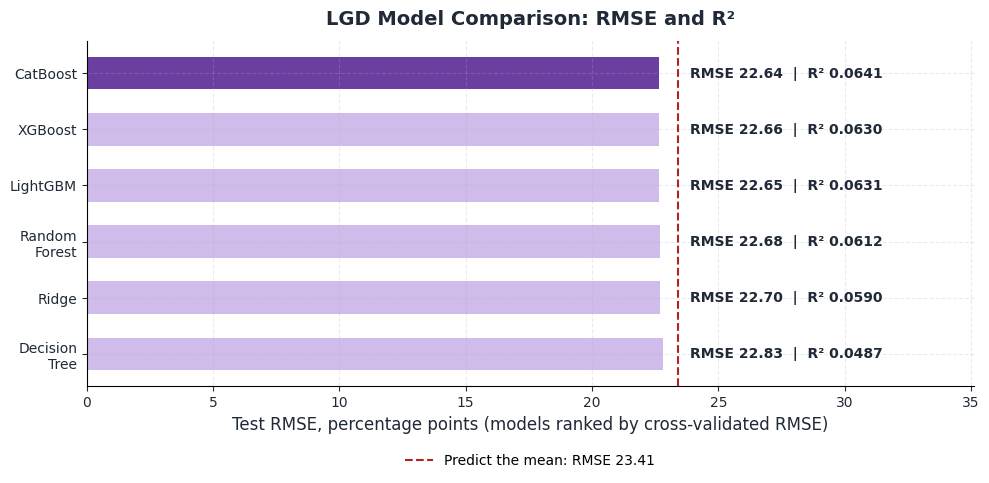

In [8]:
# Model comparison chart for the README (selected model highlighted)
plot_lgd_model_comparison(results_LGD, selected=results_LGD["cv_rmse"].idxmin(),
                          baseline_rmse=baseline_rmse_LGD)
plt.show()

## 5. SHAP Analysis

Selected model: catboost (CV RMSE 22.6928)


SHAP values shape: (20000, 76)


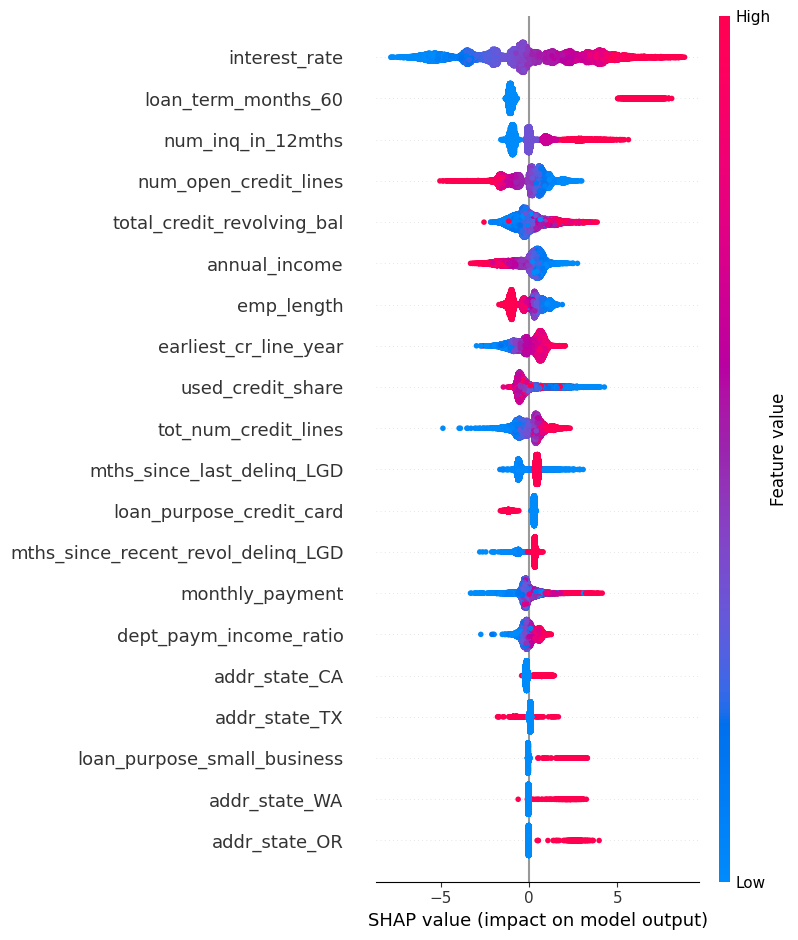

In [9]:
# Load the model with the best cross-validated RMSE
best_name_LGD = results_LGD["cv_rmse"].idxmin()
with open(f"models/{best_name_LGD}_LGD.pkl", "rb") as f:
    model_LGD = pickle.load(f)
print(f"Selected model: {best_name_LGD} (CV RMSE {results_LGD.loc[best_name_LGD, 'cv_rmse']})")

# SHAP on a representative sample
# (LinearExplainer if a linear model is selected, TreeExplainer for a tree ensemble)
X_shap_LGD = pd.concat([X_train_LGD, X_test_LGD], axis=0).sample(n=20_000, random_state=42).astype(float)
shap_values_LGD = shap_values_for(model_LGD, X_shap_LGD, X_train_LGD)

print(f"SHAP values shape: {shap_values_LGD.shape}")

shap.summary_plot(shap_values_LGD, X_shap_LGD, max_display=20, show=False)
plt.savefig("assets/shap_lgd_final.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Why the LGD is hard to predict

All six models land within 0.2 points of RMSE of each other and improve on predicting the mean by less than a point (R² about 0.06). The reason is in the target, not in the models. The LGD is measured against the amount funded, so it mixes two different things:

```
LGD = (EAD - principal repaid - recoveries) / EAD = (1 - a) * (1 - r)

a = principal repaid before default / EAD        (timing: how late the default came)
r = recoveries / balance outstanding at default  (recovery on what was still owed)
```

Two identical loans of 10,000 with the same 20% recovery give an LGD of 76% if the borrower stops paying after 3 instalments and 36% after 30. The application file is the same in both cases. The cells below measure how much of the LGD each part explains and how predictable each part is from the LGD features.

In [10]:
# Components on the defaulted, matured loans (the LGD development sample)
comp_LGD = lgd_components(df_master_features.loc[df_LGD_clean.index])
print(comp_LGD.describe(percentiles=[.1, .25, .5, .75, .9]).round(3))
print(f"\nNo recovery at all (r = 0): {(comp_LGD['r_recovered'] == 0).mean():.1%} | "
      f"recovery below 20% of the balance: {(comp_LGD['r_recovered'] < 0.2).mean():.1%}")

print("\nShare of LGD variance explained by each part alone:")
for part in ["a_repaid", "months_paid", "r_recovered"]:
    print(f"  {part:<12}: {variance_explained(comp_LGD['lgd'], comp_LGD[part]):.2f}")

print("\nLGD by instalments paid before default:")
lgd_by_months_paid(comp_LGD).round(3)

              lgd    a_repaid  r_recovered  lgd_at_default  months_paid
count  100589.000  100589.000   100576.000      100576.000   100589.000
mean       52.240       0.404        0.126          87.381       17.454
std        23.421       0.242        0.148          14.795        9.896
min         0.000       0.000        0.000           0.000        0.000
10%        18.923       0.105        0.000          76.650        5.000
25%        34.389       0.206        0.001          85.110        9.972
50%        54.486       0.372        0.104          89.621       16.308
75%        70.832       0.582        0.149          99.934       24.000
90%        81.680       0.761        0.234         100.000       30.613
max       100.000       1.000        1.000         100.000       86.784

No recovery at all (r = 0): 13.3% | recovery below 20% of the balance: 85.9%

Share of LGD variance explained by each part alone:
  a_repaid    : 0.86
  months_paid : 0.75
  r_recovered : 0.30

LGD by instal

,loans,lgd_mean,a_repaid_mean,r_recovered_mean
months_paid,,,,
"(-0.001, 6.0]",13255,81.655,0.081,0.112
"(6.0, 12.0]",21743,69.968,0.208,0.116
"(12.0, 18.0]",21666,56.652,0.354,0.124
"(18.0, 24.0]",19078,42.427,0.508,0.137
"(24.0, 36.0]",22015,24.276,0.718,0.134
"(36.0, 48.0]",2005,33.825,0.602,0.151
"(48.0, 60.0]",822,14.600,0.827,0.154
"(60.0, inf]",5,1.748,0.983,0.000


In [11]:
# How predictable is each part from the same features and split as the LGD model?
# Same fixed LightGBM for every target, so the R² values are comparable.
part_model = LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=31, min_child_samples=100,
                           subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                           random_state=42, verbose=-1)
rows = []
for part in ["lgd", "a_repaid", "months_paid", "lgd_at_default"]:
    y_tr, y_te = comp_LGD.loc[idx_train, part], comp_LGD.loc[idx_test, part]
    ok_tr, ok_te = y_tr.notna(), y_te.notna()
    part_model.fit(X_train_LGD[ok_tr.values], y_tr[ok_tr])
    rows.append({"target": part, "test_R2": r2_score(y_te[ok_te], part_model.predict(X_test_LGD[ok_te.values])),
                 "mean": y_tr.mean(), "std": y_tr.std()})
pd.DataFrame(rows).set_index("target").round(3)

,test_R2,mean,std
target,,,
lgd,0.064,52.254,23.425
a_repaid,0.076,0.404,0.242
months_paid,0.084,17.447,9.899
lgd_at_default,0.006,87.369,14.814


### Reading the decomposition

- **Timing drives the LGD.** The share of principal repaid before default explains most of the variance of the LGD on its own (see the first cell). A default in the first six months loses around 80% of the amount funded; one after two to three years loses around a quarter.
- **Timing is barely predictable at origination.** The features explain only a few percent of `a_repaid` and of the months paid. When a borrower stops paying depends on events after the loan is granted (job loss, illness, other debts), which no application field records.
- **The recovery is almost constant.** Most defaults recover less than 20% of what was still owed; the loss on the balance at default (`lgd_at_default`) is high and stable, and the features explain essentially none of it.

So the low R² is a property of the target on unsecured consumer loans with application data, not a modelling failure, and more complex models would not change it. What the Expected Loss needs is the right **level** of LGD by segment, and section 7 checks that the predicted mean matches the observed one.

**Possible improvement (not implemented): the Basel structure.** Regulatory IRB models separate the two parts: EAD is the balance outstanding at default (for an amortising loan, the amortisation schedule evaluated at the expected default date) and LGD is the loss on that balance, `1 - r`. The Expected Loss is the same product, but each component then has a clear meaning: a timing model for EAD and an LGD close to a constant of about 87% for this portfolio. It would change notebooks 01, 06 and 07 and add a model for the default date.

## 7. LGD Inference on Full Portfolio

The LGD model is applied to the full portfolio, including non-defaulted and not yet matured loans, through the pipeline fitted on the training split. This is standard practice in Basel IRB: the question is what would be lost if each loan defaulted. Its main limitation is that performing loans may sit outside the feature ranges seen on defaulted loans, which the fitted caps only partly control. Predictions are clipped to [0, 100], the range of the target.

In [12]:
# Whole portfolio through the pipeline fitted on the training split
X_full_LGD = pipeline_LGD.transform(df_master_features[features_LGD])
print(f"X_full_LGD shape: {X_full_LGD.shape}")

X_full_LGD shape: (2139643, 76)


In [13]:
# Inference, clipped to the range of the target
y_pred_raw = model_LGD.predict(X_full_LGD)
y_pred_LGD = np.clip(y_pred_raw, 0, 100)
df_master_features["LGD"] = y_pred_LGD

print(f"LGD computed for {len(y_pred_LGD):,} loans")
print(f"Predictions outside [0, 100] before clipping: {np.mean((y_pred_raw < 0) | (y_pred_raw > 100)):.4%}")
print(f"Mean LGD   : {y_pred_LGD.mean():.4f}")
print(f"Median LGD : {np.median(y_pred_LGD):.4f}")

LGD computed for 2,139,643 loans
Predictions outside [0, 100] before clipping: 0.0000%
Mean LGD   : 52.3573
Median LGD : 51.5349


In [14]:
# Calibration check: predicted vs observed LGD where the outcome is complete
for name, idx in [("development sample (defaulted, matured)", df_LGD_clean.index),
                  ("test split", idx_test)]:
    pred = df_master_features.loc[idx, "LGD"]
    real = df_master_features.loc[idx, "Target_Variable_Loss"]
    print(f"{name}: mean predicted {pred.mean():.2f} | mean observed {real.mean():.2f} | "
          f"median predicted {pred.median():.2f} | median observed {real.median():.2f}")

development sample (defaulted, matured): mean predicted 52.25 | mean observed 52.24 | median predicted 51.70 | median observed 54.49
test split: mean predicted 52.22 | mean observed 52.18 | median predicted 51.69 | median observed 54.34


In [15]:
# Save pipeline and df_master_features with PD and LGD columns
pipeline_LGD.save("models/pipeline_LGD.pkl")

with open("data/processed/checkpoint_df_master_with_PD_LGD.pkl", "wb") as f:
    pickle.dump({"df_master_features": df_master_features}, f)

print("Saved pipeline and df_master_features with PD and LGD columns.")

Pipeline saved to models/pipeline_LGD.pkl


Saved pipeline and df_master_features with PD and LGD columns.
